## Tugas Praktikum 6: Clustering (Advance)

|     NRP      |     Nama       |
|-----------   |-------------   |
| 5054251013   | Evina Fitriyani| 

## 1. Import Dataset

Dataset yang dipakai Palmer Penguins (Horst, Hill, dan Gorman, 2020), berisi 344 baris hasil pengukuran penguin di Kepulauan Palmer, Antartika. Fitur clustering ada empat kolom numerik: bill_length_mm, bill_depth_mm, flipper_length_mm, dan body_mass_g. Kolom species cuma dipakai buat pembanding saat evaluasi, tidak ikut clustering.

Data set: https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv


In [1]:
# import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None) 

In [2]:
# baca dataset langsung dari link

url = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(url)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
# cek ukuran data, harusnya 344 baris 8 kolom

print(df.shape)

(344, 8)


In [4]:
# cek tipe data tiap kolom dan jumlah non-null nya

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Eksplorasi dan Pembersihan Data

### 2.1 Eksplorasi Data

Dicek dulu ada berapa nilai kosong di tiap kolom, lalu baris yang kosong di empat kolom numerik atau di kolom species dibuang.


In [5]:
# jumlah nilai kosong tiap kolom

df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [6]:
# simpan jumlah baris dan jumlah data per spesies sebelum dibersihkan

fitur = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

baris_awal = df.shape[0]
species_awal = df['species'].value_counts()

print('Jumlah baris sebelum cleaning:', baris_awal)
print(species_awal)

Jumlah baris sebelum cleaning: 344
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


### 2.2 Pembersihan Data

Baris yang nilainya kosong di salah satu dari empat kolom numerik atau di kolom species dibuang.


In [7]:
# buang baris yang kosong di kolom fitur atau species

df_clean = df.dropna(subset=fitur + ['species']).copy()
df_clean = df_clean.reset_index(drop=True)

print('Jumlah baris sesudah cleaning:', df_clean.shape[0])
print(df_clean['species'].value_counts())

Jumlah baris sesudah cleaning: 342
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


In [8]:
# perbandingan jumlah data per spesies sebelum dan sesudah cleaning

perbandingan = pd.DataFrame({
    'Sebelum': species_awal,
    'Sesudah': df_clean['species'].value_counts()
})
perbandingan.loc['Total'] = perbandingan.sum()
perbandingan

,Sebelum,Sesudah
species,,
Adelie,152,151
Gentoo,124,123
Chinstrap,68,68
Total,344,342


In [9]:
# statistik deskriptif, perhatiin perbedaan skala antar kolom

df_clean[fitur].describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


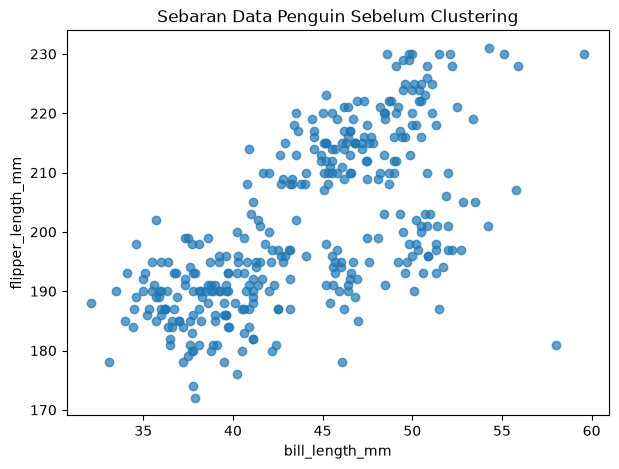

In [10]:
# scatter plot awal sebelum clustering

plt.figure(figsize=(7,5))
plt.scatter(df_clean['bill_length_mm'], df_clean['flipper_length_mm'], alpha=0.7)
plt.xlabel('bill_length_mm')
plt.ylabel('flipper_length_mm')
plt.title('Sebaran Data Penguin Sebelum Clustering')
plt.show()

## 3. Standardisasi Data

Matriks fitur X diambil dari empat kolom numerik, dan kolom species disimpan di y buat pembanding. Skala antar kolom beda jauh (milimeter dan gram), jadi X distandardisasi pakai z-score. Semua algoritma di bawah dijalankan di data hasil standardisasi ini.


In [11]:
# pisahkan X dan y

X = df_clean[fitur].values
y = df_clean['species'].values

print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (342, 4)
Shape y: (342,)


In [12]:
# standardisasi X pakai z-score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=fitur)
df_scaled.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-2.17,-2.05,-2.06,-1.88
25%,-0.86,-0.79,-0.78,-0.81
50%,0.10,0.08,-0.28,-0.19
75%,0.84,0.79,0.86,0.68
max,2.88,2.21,2.14,2.62


## 4. Penerapan Algoritma

### 4.1 Agglomerative Clustering

Jumlah kluster 3 dengan linkage ward.


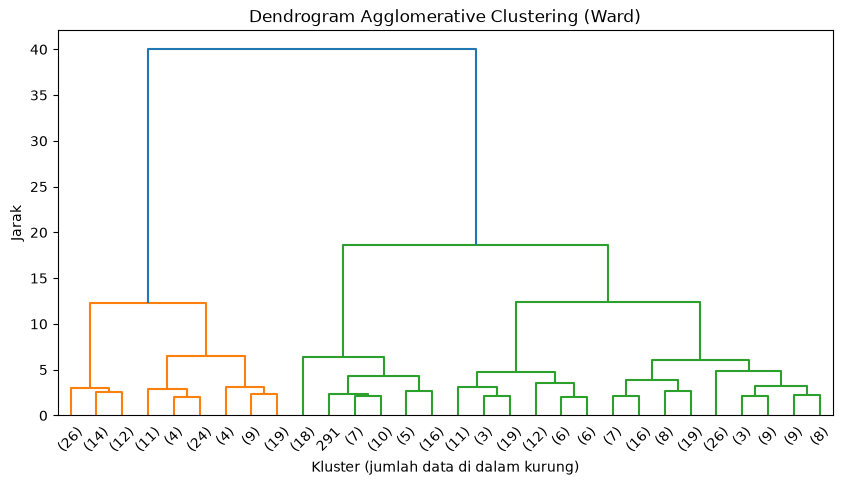

In [13]:
# dendrogram agglomerative (linkage ward), dipotong di 30 kluster terakhir biar kebaca

link = linkage(X_scaled, method='ward')

plt.figure(figsize=(10,5))
dendrogram(link, truncate_mode='lastp', p=30)
plt.title('Dendrogram Agglomerative Clustering (Ward)')
plt.xlabel('Kluster (jumlah data di dalam kurung)')
plt.ylabel('Jarak')
plt.show()

In [14]:
# agglomerative clustering dengan 3 kluster

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
label_agg = agg.fit_predict(X_scaled)

print(pd.Series(label_agg).value_counts().sort_index())

0    162
1    123
2     57
Name: count, dtype: int64


### 4.2 DBSCAN

Mulai dari eps 0.5 dan MinPts 5, lalu dicoba beberapa nilai eps lain buat ngeliat jumlah kluster dan jumlah titik noise.


In [15]:
# DBSCAN dengan beberapa nilai eps (MinPts tetap 5)

hasil_eps = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    label = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    jumlah_kluster = len(set(label)) - (1 if -1 in label else 0)
    jumlah_noise = (label == -1).sum()
    hasil_eps.append([eps, jumlah_kluster, jumlah_noise])

tabel_eps = pd.DataFrame(hasil_eps, columns=['eps', 'Jumlah Kluster', 'Jumlah Noise'])
tabel_eps

,eps,Jumlah Kluster,Jumlah Noise
0,0.3,4,317
1,0.4,10,171
2,0.5,4,69
3,0.6,2,33
4,0.7,2,16
5,0.8,2,5
6,1.0,2,1


In [16]:
# DBSCAN yang dipakai buat perbandingan (ganti eps_pilih kalau mau pakai nilai lain)

eps_pilih = 0.5

dbscan = DBSCAN(eps=eps_pilih, min_samples=5)
label_db = dbscan.fit_predict(X_scaled)

print('eps:', eps_pilih)
print('Jumlah kluster:', len(set(label_db)) - (1 if -1 in label_db else 0))
print('Jumlah noise:', (label_db == -1).sum())

eps: 0.5
Jumlah kluster: 4
Jumlah noise: 69


### 4.3 Gaussian Mixture Models (GMM)

Jumlah komponen 3.


In [17]:
# GMM dengan 3 komponen

gmm = GaussianMixture(n_components=3, random_state=42)
label_gmm = gmm.fit_predict(X_scaled)

print(pd.Series(label_gmm).value_counts().sort_index())

0     67
1    123
2    152
Name: count, dtype: int64


### 4.4 Spectral Clustering

Jumlah kluster 3.


In [18]:
# spectral clustering dengan 3 kluster

spec = SpectralClustering(n_clusters=3, random_state=42)
label_spec = spec.fit_predict(X_scaled)

print(pd.Series(label_spec).value_counts().sort_index())

0    176
1    123
2     43
Name: count, dtype: int64


### 4.5 Visualisasi Hasil Clustering

Scatter plot hasil tiap algoritma, satu warna buat tiap kluster. Titik noise DBSCAN (label -1) diberi warna abu-abu terpisah.


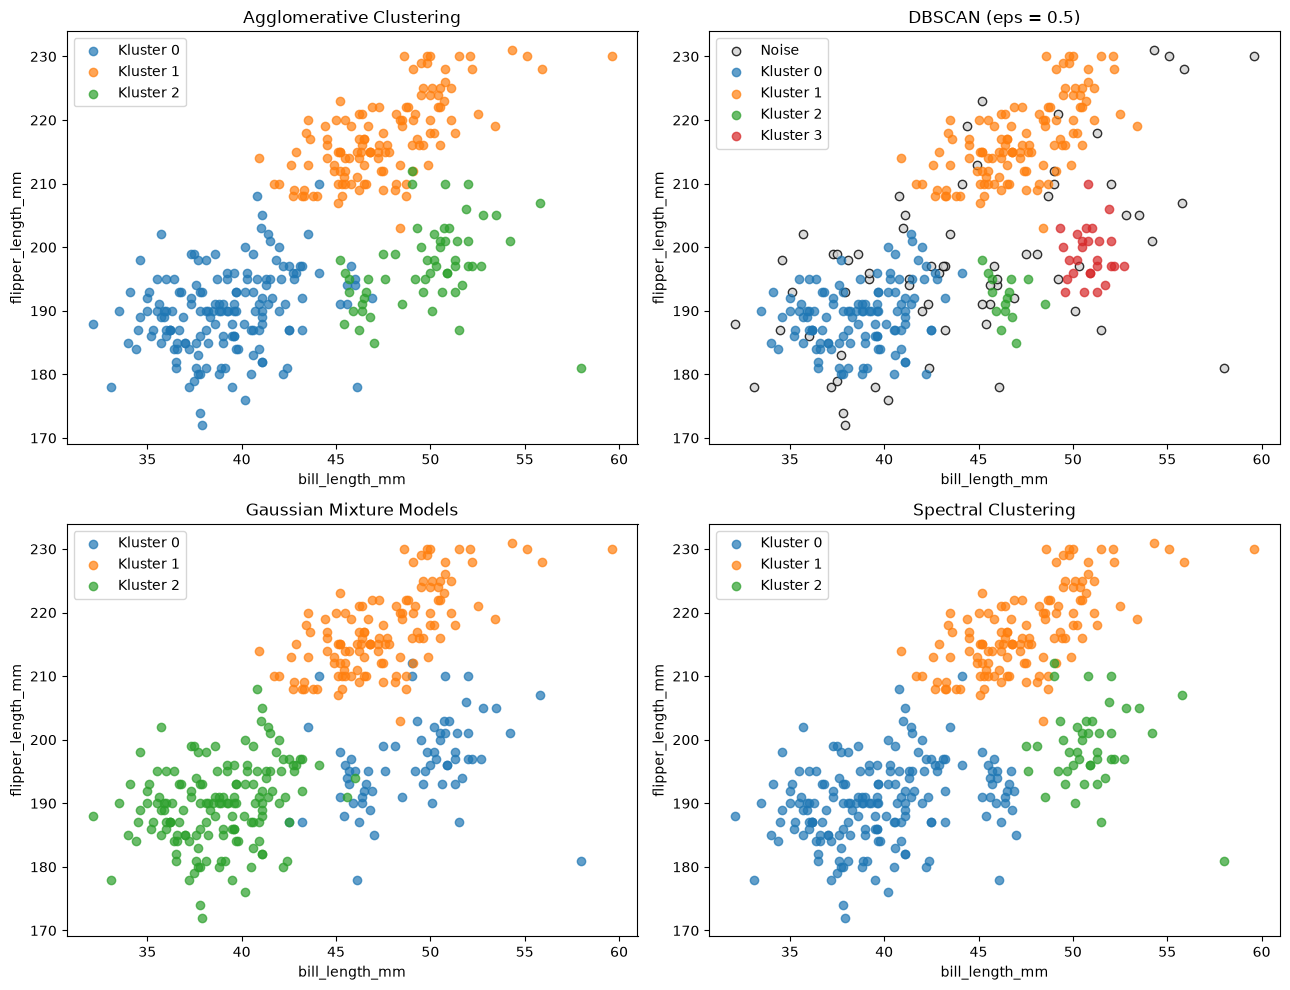

In [19]:
# scatter plot hasil keempat algoritma (sumbu pakai data asli biar mudah dibaca)

def gambar(ax, label, judul):
    for k in sorted(set(label)):
        m = label == k
        if k == -1:
            ax.scatter(X[m, 0], X[m, 2], c='lightgrey', edgecolor='black', label='Noise', alpha=0.8)
        else:
            ax.scatter(X[m, 0], X[m, 2], label='Kluster ' + str(k), alpha=0.7)
    ax.set_title(judul)
    ax.set_xlabel('bill_length_mm')
    ax.set_ylabel('flipper_length_mm')
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
gambar(axes[0, 0], label_agg, 'Agglomerative Clustering')
gambar(axes[0, 1], label_db, 'DBSCAN (eps = ' + str(eps_pilih) + ')')
gambar(axes[1, 0], label_gmm, 'Gaussian Mixture Models')
gambar(axes[1, 1], label_spec, 'Spectral Clustering')
plt.tight_layout()
plt.show()

## 5. Evaluasi Hasil Clustering

### 5.1 Silhouette Score, Rand Index, dan NMI

Silhouette Score dihitung di data hasil standardisasi. Buat DBSCAN, titik noise nggak ikut dihitung di Silhouette Score. Rand Index dan NMI dihitung terhadap kolom species, dan di DBSCAN noise dianggap satu kelompok sendiri (label -1).


In [20]:
# hitung Silhouette Score, Rand Index, dan NMI tiap algoritma

semua_label = {
    'Agglomerative': label_agg,
    'DBSCAN': label_db,
    'GMM': label_gmm,
    'Spectral': label_spec
}

nilai = []
for nama, label in semua_label.items():
    bukan_noise = label != -1
    sil = silhouette_score(X_scaled[bukan_noise], label[bukan_noise])
    ri = rand_score(y, label)
    nmi = normalized_mutual_info_score(y, label)
    nilai.append([nama, sil, ri, nmi])
    if nama == 'DBSCAN':
        print('DBSCAN: titik noise yang dibuang dari Silhouette =', (~bukan_noise).sum())

tabel_nilai = pd.DataFrame(nilai, columns=['Algoritma', 'Silhouette', 'Rand Index', 'NMI'])
tabel_nilai.round(4)

DBSCAN: titik noise yang dibuang dari Silhouette = 69


,Algoritma,Silhouette,Rand Index,NMI
0,Agglomerative,0.4541,0.9608,0.9007
1,DBSCAN,0.4235,0.8525,0.6631
2,GMM,0.4545,0.9817,0.9349
3,Spectral,0.4624,0.9168,0.8312


### 5.2 Uji Kestabilan

Tiap algoritma dijalankan ulang di 90% data yang diambil acak sebanyak tiga kali. Hasilnya dibandingin sama hasil di data penuh (di titik yang sama) pakai Rand Index dan NMI. Makin dekat ke 1 berarti makin stabil.


In [21]:
# fungsi buat menjalankan tiap algoritma di data tertentu

def jalankan(nama, data):
    if nama == 'Agglomerative':
        return AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(data)
    if nama == 'DBSCAN':
        return DBSCAN(eps=eps_pilih, min_samples=5).fit_predict(data)
    if nama == 'GMM':
        return GaussianMixture(n_components=3, random_state=42).fit_predict(data)
    if nama == 'Spectral':
        return SpectralClustering(n_clusters=3, random_state=42).fit_predict(data)

In [22]:
# uji kestabilan: 3 kali ambil 90% data acak

n = X_scaled.shape[0]
jumlah_sampel = int(0.9 * n)

detail = []
for nama in semua_label.keys():
    for ulangan in range(3):
        rng = np.random.RandomState(ulangan)
        idx = rng.choice(n, jumlah_sampel, replace=False)
        label_sampel = jalankan(nama, X_scaled[idx])
        label_penuh = semua_label[nama][idx]
        ri = rand_score(label_penuh, label_sampel)
        nmi = normalized_mutual_info_score(label_penuh, label_sampel)
        detail.append([nama, ulangan + 1, ri, nmi])

tabel_stabil = pd.DataFrame(detail, columns=['Algoritma', 'Ulangan', 'Rand Index', 'NMI'])
tabel_stabil.round(4)

,Algoritma,Ulangan,Rand Index,NMI
0,Agglomerative,1,1.0000,1.0000
1,Agglomerative,2,0.9796,0.9388
2,Agglomerative,3,0.9759,0.9303
3,DBSCAN,1,0.9888,0.9517
4,DBSCAN,2,0.9750,0.9247
5,DBSCAN,3,0.9722,0.9274
6,GMM,1,0.9958,0.9827
7,GMM,2,0.7616,0.6710
8,GMM,3,1.0000,1.0000
9,Spectral,1,0.9958,0.9819


In [23]:
# rata-rata kestabilan tiap algoritma

rata_stabil = tabel_stabil.groupby('Algoritma')[['Rand Index', 'NMI']].mean()
rata_stabil.columns = ['Stabil Rand Index', 'Stabil NMI']
rata_stabil.round(4)

,Stabil Rand Index,Stabil NMI
Algoritma,,
Agglomerative,0.9851,0.9563
DBSCAN,0.9787,0.9346
GMM,0.9192,0.8846
Spectral,0.9986,0.9940


### 5.3 Tabel Perbandingan

Semua nilai evaluasi dirangkum dalam satu tabel.


In [24]:
# tabel perbandingan semua algoritma

jumlah_kluster = {
    nama: len(set(label)) - (1 if -1 in label else 0) for nama, label in semua_label.items()
}
jumlah_noise = {nama: int((label == -1).sum()) for nama, label in semua_label.items()}

perbandingan_akhir = tabel_nilai.set_index('Algoritma').join(rata_stabil)
perbandingan_akhir.insert(0, 'Jumlah Noise', pd.Series(jumlah_noise))
perbandingan_akhir.insert(0, 'Jumlah Kluster', pd.Series(jumlah_kluster))
perbandingan_akhir.round(4)

,Jumlah Kluster,Jumlah Noise,Silhouette,Rand Index,NMI,Stabil Rand Index,Stabil NMI
Algoritma,,,,,,,
Agglomerative,3,0,0.4541,0.9608,0.9007,0.9851,0.9563
DBSCAN,4,69,0.4235,0.8525,0.6631,0.9787,0.9346
GMM,3,0,0.4545,0.9817,0.9349,0.9192,0.8846
Spectral,3,0,0.4624,0.9168,0.8312,0.9986,0.9940


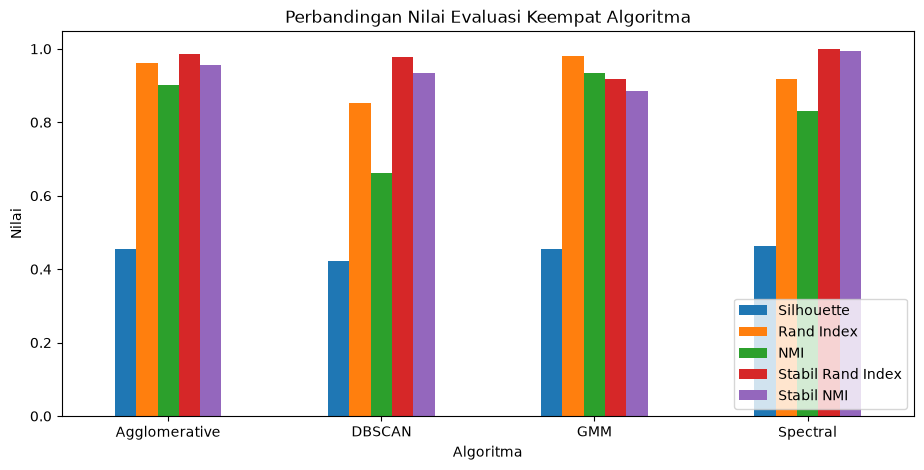

In [25]:
# visualisasi perbandingan nilai evaluasi

perbandingan_akhir[['Silhouette', 'Rand Index', 'NMI', 'Stabil Rand Index', 'Stabil NMI']].plot(kind='bar', figsize=(11,5), rot=0)
plt.title('Perbandingan Nilai Evaluasi Keempat Algoritma')
plt.ylabel('Nilai')
plt.legend(loc='lower right')
plt.show()

## Ringkasan
- Dataset awal: 344 baris, 8 kolom
- Baris yang kosong di empat kolom fitur atau di kolom species dibuang
- Empat kolom numerik distandardisasi pakai z-score, kolom species cuma jadi label pembanding
- Algoritma yang dipakai: Agglomerative (ward, 3 kluster), DBSCAN (MinPts 5), GMM (3 komponen), Spectral (3 kluster)
- Evaluasi: Silhouette Score, Rand Index, NMI, dan uji kestabilan 3 kali di 90% data
- (isi sisanya setelah output keluar)